# Setup

In [ ]:
# from google.colab import files
# files.upload()

!pip install kagglehub



   ----------------------------------------  0/10 [urllib3]
   ----------------------------------------  0/10 [urllib3]
   ---- -----------------------------------  1/10 [tqdm]
   ---- -----------------------------------  1/10 [tqdm]
   -------- -------------------------------  2/10 [pyyaml]
   ------------ ---------------------------  3/10 [protobuf]
   ------------ ---------------------------  3/10 [protobuf]
   ------------ ---------------------------  3/10 [protobuf]
   ------------ ---------------------------  3/10 [protobuf]
   ------------ ---------------------------  3/10 [protobuf]
   ---------------- -----------------------  4/10 [idna]
   -------------------- -------------------  5/10 [charset_normalizer]
   ------------------------ ---------------  6/10 [certifi]
   ---------------------------- -----------  7/10 [requests]
   -------------------------------- -------  8/10 [kagglesdk]
   -------------------------------- -------  8/10 [kagglesdk]
   -------------------------

In [ ]:
import kagglehub
from google.colab import userdata
import os
os.environ["KAGGLE_USERNAME"] = userdata.get('KAGGLE_USERNAME')
os.environ["KAGGLE_KEY"] = userdata.get('KAGGLE_KEY')

path = kagglehub.dataset_download("yash92328/ai4mars-terrainaware-autonomous-driving-on-mars")
print(path)

d:\lucasfan\Programming\Projects\Python\mlsn-group-5\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ModuleNotFoundError: No module named 'google.colab'

In [ ]:
import glob

MSL = glob.glob(os.path.join(path, "**", "msl"), recursive=True)[0]
print("msl folder:", MSL)

EDR_DIR = os.path.join(MSL, "images", "edr")
MXY_DIR = os.path.join(MSL, "images", "mxy")
RNG_DIR = os.path.join(MSL, "images", "rng-30m")
TRAIN_LABEL_DIR = os.path.join(MSL, "labels", "train")
print(os.listdir(os.path.join(MSL, "labels", "test")))

NameError: name 'os' is not defined

In [ ]:
TEST_LABEL_DIR = os.path.join(MSL, "labels", "test", "masked-gold-min3-100agree")

for name, d in [("edr", EDR_DIR), ("mxy", MXY_DIR), ("rng", RNG_DIR),
                ("train labels", TRAIN_LABEL_DIR), ("test labels", TEST_LABEL_DIR)]:
    files = sorted(os.listdir(d))
    print(f"{name}: {len(files)} files, e.g. {files[:2]}")

edr: 18130 files, e.g. ['NLA_397586928EDR_F0010008AUT_04096M1.JPG', 'NLA_397586934EDR_F0010008AUT_04096M1.JPG']
mxy: 18097 files, e.g. ['NLA_397586928MXY_F0010008AUT_04096M1.png', 'NLA_397586934MXY_F0010008AUT_04096M1.png']
rng: 18096 files, e.g. ['NLA_397586928RNG_F0010008AUT_04096M1.png', 'NLA_397586934RNG_F0010008AUT_04096M1.png']
train labels: 16064 files, e.g. ['NLA_397586934EDR_F0010008AUT_04096M1.png', 'NLA_397681339EDR_F0020000AUT_04096M1.png']
test labels: 322 files, e.g. ['NLA_409036068EDR_F0051606NCAM00348M1_merged.png', 'NLA_409036116EDR_F0051606NCAM00348M1_merged.png']


# Task #1: Random sample

In [ ]:
import random

train_labels = sorted(f for f in os.listdir(TRAIN_LABEL_DIR) if f.endswith(".png"))
test_labels = sorted(f for f in os.listdir(TEST_LABEL_DIR) if f.endswith(".png"))

random.seed(42)
train_sample = random.sample(train_labels, 500)
test_sample = random.sample(test_labels, 125)

print(len(train_sample), "train", len(test_sample), "test")
print(train_sample[:3])
print(test_sample[:3])

NameError: name 'os' is not defined

In [ ]:
# Making sure we get the right amount of files, no duplicates, and that all the files are real train files

print(len(train_sample) == 500, len(test_sample) == 125) # checks if file amount is right
print(len(set(train_sample)) == 500) # checks for duplicates
print(all(f in train_labels for f in train_sample)) # checks if all train files are real

True True
True
True


# Task #2: Check files, sizes, and label values

In [ ]:
def get_paths(label_file, split):
  """Given a label file name, return the paths to its photo, masks, and label."""
  base = label_file.replace(".png", "")
  if split == "test":
    base = base.replace("_merged", "")
    label_dir = TEST_LABEL_DIR
  else:
    label_dir = TRAIN_LABEL_DIR

  return {
      "edr":   os.path.join(EDR_DIR, base + ".JPG"),
      "mxy":   os.path.join(MXY_DIR, base.replace("EDR", "MXY") + ".png"),
      "rng":   os.path.join(RNG_DIR, base.replace("EDR", "RNG") + ".png"),
      "label": os.path.join(label_dir, label_file),
  }

print(get_paths(train_sample[0], "train"))
print(get_paths(test_sample[0], "test"))

{'edr': '/root/.cache/kagglehub/datasets/yash92328/ai4mars-terrainaware-autonomous-driving-on-mars/versions/1/ai4mars-dataset-merged-0.1/msl/images/edr/NLB_532342701EDR_F0592578NCAM00279M1.JPG', 'mxy': '/root/.cache/kagglehub/datasets/yash92328/ai4mars-terrainaware-autonomous-driving-on-mars/versions/1/ai4mars-dataset-merged-0.1/msl/images/mxy/NLB_532342701MXY_F0592578NCAM00279M1.png', 'rng': '/root/.cache/kagglehub/datasets/yash92328/ai4mars-terrainaware-autonomous-driving-on-mars/versions/1/ai4mars-dataset-merged-0.1/msl/images/rng-30m/NLB_532342701RNG_F0592578NCAM00279M1.png', 'label': '/root/.cache/kagglehub/datasets/yash92328/ai4mars-terrainaware-autonomous-driving-on-mars/versions/1/ai4mars-dataset-merged-0.1/msl/labels/train/NLB_532342701EDR_F0592578NCAM00279M1.png'}
{'edr': '/root/.cache/kagglehub/datasets/yash92328/ai4mars-terrainaware-autonomous-driving-on-mars/versions/1/ai4mars-dataset-merged-0.1/msl/images/edr/NLB_520358689EDR_F0550940NCAM00299M1.JPG', 'mxy': '/root/.cache

In [ ]:
import numpy as np
from PIL import Image

ALLOWED = {0, 1, 2, 3, 255}

def check(label_file, split):
  """Return a list of problems with this image. An empty list means it passed."""
  paths = get_paths(label_file, split)

  # First check to make sure all the files exist
  problems = []
  for kind, p in paths.items():
    if not os.path.exists(p):
      problems.append(f"missing {kind}")
  if problems:
    return problems

  # Second check to mae sure all four are hte same size
  sizes = {kind: Image.open(p).size for kind, p in paths.items()}
  if len(set(sizes.values())) > 1:
    problems.append(f"size mismatch {sizes}")

  # Third check to make sure that the label only uses allowed values
  label = np.array(Image.open(paths["label"]))
  bad = set(np.unique(label).tolist()) - ALLOWED
  if bad:
    problems.append(f"bad label values {bad}")

  return problems

print(check(train_sample[0], "train"))

[]


In [ ]:
# Just making sure checker can actually fail
print(check("NLA_FAKE123EDR_TEST.png", "train"))

['missing edr', 'missing mxy', 'missing rng', 'missing label']


In [ ]:
results = []
for split, sample in [("train", train_sample), ("test", test_sample)]:
  for f in sample:
    results.append({"split": split, "label_file": f, "problems": check(f, split)})

failed = [r for r in results if r["problems"]]
print(f"{len(failed)} of {len(results)} images failed")
for r in failed:
  print(r["split"], r["label_file"], r["problems"])

0 of 625 images failed


In [ ]:
import pandas as pd

rows = []
for r in results:
  paths = get_paths(r["label_file"], r["split"])
  row = {"split": r["split"]}
  for kind, p in paths.items():
    row[kind] = os.path.relpath(p, MSL)
  row["passed"] = len(r["problems"]) == 0
  rows.append(row)

df = pd.DataFrame(rows)
df.to_csv("sample_split.csv", index=False)
print(df.shape)
df.head()

(625, 6)


,split,edr,mxy,rng,label,passed
0,train,images/edr/NLB_532342701EDR_F0592578NCAM00279M...,images/mxy/NLB_532342701MXY_F0592578NCAM00279M...,images/rng-30m/NLB_532342701RNG_F0592578NCAM00...,labels/train/NLB_532342701EDR_F0592578NCAM0027...,True
1,train,images/edr/NLB_424934381EDR_F0060658NCAM00247M...,images/mxy/NLB_424934381MXY_F0060658NCAM00247M...,images/rng-30m/NLB_424934381RNG_F0060658NCAM00...,labels/train/NLB_424934381EDR_F0060658NCAM0024...,True
2,train,images/edr/NLA_402816098EDR_F0050104NCAM00451M...,images/mxy/NLA_402816098MXY_F0050104NCAM00451M...,images/rng-30m/NLA_402816098RNG_F0050104NCAM00...,labels/train/NLA_402816098EDR_F0050104NCAM0045...,True
3,train,images/edr/NLB_550280573EDR_F0633092NCAM00312M...,images/mxy/NLB_550280573MXY_F0633092NCAM00312M...,images/rng-30m/NLB_550280573RNG_F0633092NCAM00...,labels/train/NLB_550280573EDR_F0633092NCAM0031...,True
4,train,images/edr/NLB_454665258EDR_F0331036NCAM00293M...,images/mxy/NLB_454665258MXY_F0331036NCAM00293M...,images/rng-30m/NLB_454665258RNG_F0331036NCAM00...,labels/train/NLB_454665258EDR_F0331036NCAM0029...,True


**Result:** 0 of 625 sampled images failed. All have edr/mxy/rng/label files, matching sizes, and only label values {0, 1, 2, 3, 255}.

Note: the full dataset has 33 photos missing MXY masks and 34 missing RNG masks, but none landed in this sample.

# Task #3: Check images, create threshold

In [ ]:
# hey guys
import matplotlib.pyplot as plt

NULL_VALUE = 255

def labeled_fraction(label_file, split):
  """Return the fraction of pixels in a label that are NOT 255 (i.e. labeled)."""
  paths = get_paths(label_file, split)
  label = np.array(Image.open(paths["label"]))
  return (label != NULL_VALUE).sum() / label.size

# Test it on one image before running everything
# print(labeled_fraction(train_sample[0], "train"))

# Add label_file and labeled_frac to the df from Task #2
df["label_file"] = [r["label_file"] for r in results]
df["labeled_frac"] = [labeled_fraction(r["label_file"], r["split"]) for r in results]

print(df.groupby("split")["labeled_frac"].describe())

ModuleNotFoundError: No module named 'matplotlib'

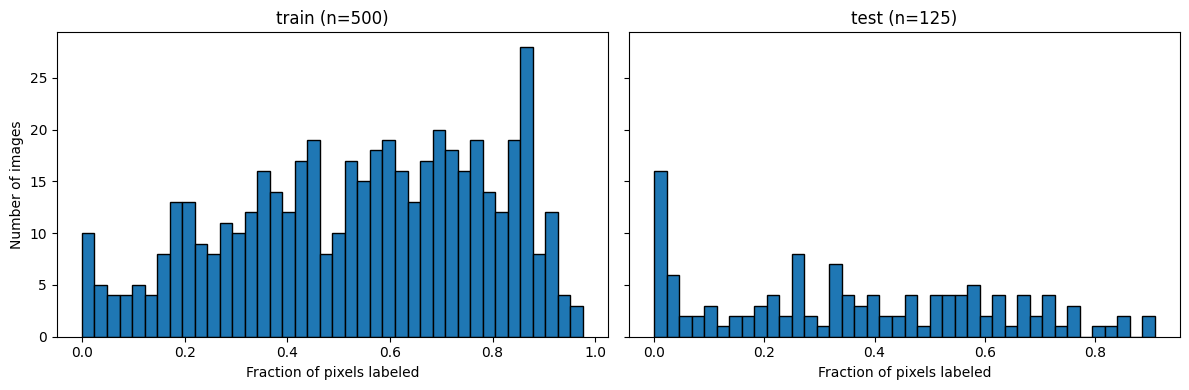

In [ ]:
# Plot 1: histogram of labeled fraction

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, split in zip(axes, ["train", "test"]):
  vals = df.loc[df.split == split, "labeled_frac"]
  ax.hist(vals, bins=40, edgecolor="black")
  ax.set_title(f"{split} (n={len(vals)})")
  ax.set_xlabel("Fraction of pixels labeled")
axes[0].set_ylabel("Number of images")
plt.tight_layout()
plt.show()

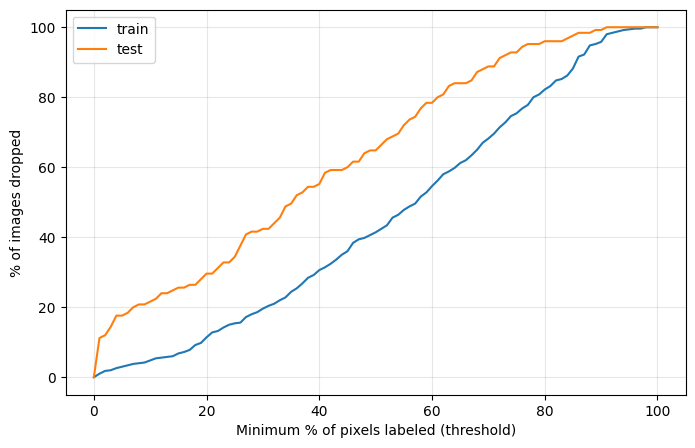

In [ ]:
# Plot 2: how many images would each threshold drop?

thresholds = np.linspace(0, 1, 101)

plt.figure(figsize=(8, 5))
for split in ["train", "test"]:
  vals = df.loc[df.split == split, "labeled_frac"].values
  dropped = [(vals < t).mean() * 100 for t in thresholds]
  plt.plot(thresholds * 100, dropped, label=split)

plt.xlabel("Minimum % of pixels labeled (threshold)")
plt.ylabel("% of images dropped")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [ ]:
# Apply the threshold

THRESHOLD = 0.10  # may change later

# Keep all test images; only filter train
df["keep"] = (df["split"] == "test") | (df["labeled_frac"] >= THRESHOLD)

print(df.groupby("split")["keep"].agg(kept="sum", total="count"))
print(f"Dropped: {(~df.keep).sum()} of {len(df)}")

df.to_csv("sample_split_filtered.csv", index=False)

df_kept = df[df.keep]
print(df_kept.shape)

       kept  total
split             
test    125    125
train   476    500
Dropped: 24 of 625
(601, 9)


# Task #4: Pixel Count

In [8]:
import os
import glob
import random
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Load the dataset
path = kagglehub.dataset_download(
    "yash92328/ai4mars-terrainaware-autonomous-driving-on-mars"
)
MSL = glob.glob(os.path.join(path, "**", "msl"), recursive=True)[0]
TRAIN_LABEL_DIR = os.path.join(MSL, "labels", "train")
NULL_VALUE = 255

# Use the same 500-image training subset as Task 1
train_labels = sorted(
    f for f in os.listdir(TRAIN_LABEL_DIR) if f.endswith(".png")
)
random.seed(42)
train_sample = random.sample(train_labels, 500)

CLASSES = [0, 1, 2, 3]
CLASS_LABELS = ["soil", "bedrock", "sand", "big rock"]
N = len(train_sample)

pixel_counts = np.zeros(len(CLASSES), dtype=np.int64)
image_counts = np.zeros(len(CLASSES), dtype=np.int64)
heat = None
labeled_total = 0
resized = 0

100%|██████████| 5.72G/5.72G [01:09<00:00, 89.0MB/s]

Extracting files...


In [9]:
# Count pixels and images containing each class
for f in train_sample:
  with Image.open(os.path.join(TRAIN_LABEL_DIR, f)) as img:
    label = np.array(img)

  counts = np.bincount(label[label != NULL_VALUE], minlength=len(CLASSES))
  pixel_counts += counts
  image_counts += counts > 0
  labeled_total += (label != NULL_VALUE).sum()

  # Resize only for the heatmaps; pixel counts use the original size
  if heat is None:
    heat = np.zeros((len(CLASSES),) + label.shape)
  if label.shape != heat.shape[1:]:
    label = np.array(Image.fromarray(label).resize(
        (heat.shape[2], heat.shape[1]), resample=Image.NEAREST
    ))
    resized += 1

  for c in CLASSES:
    heat[c] += label == c

heat /= N

500 training images, heatmap size 1024x1024, 0 masks resized
   class    pixels  % of labeled pixels  images with class  % of images
    soil 105264360                37.10                252         50.4
 bedrock 140456739                49.50                323         64.6
    sand  34015503                11.99                179         35.8
big rock   4016638                 1.42                 80         16.0


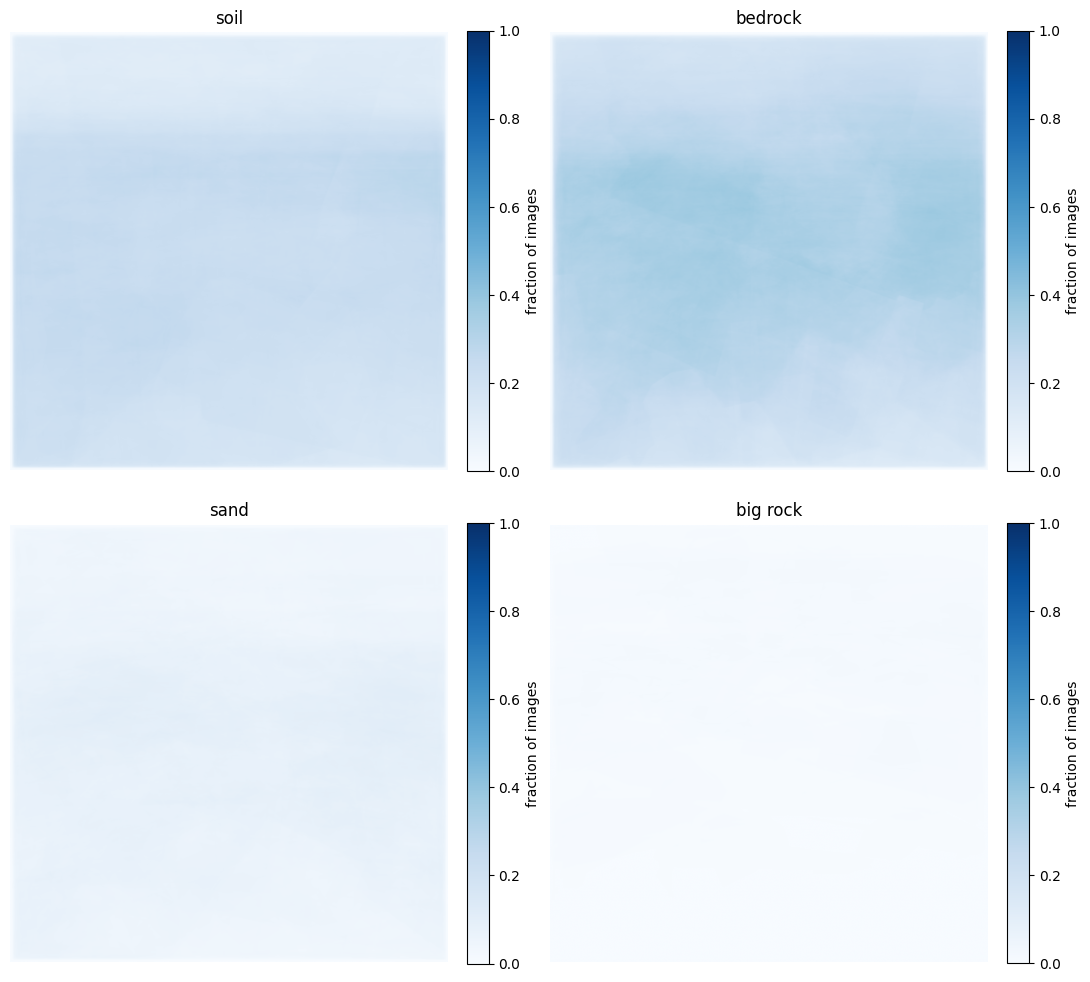

In [10]:
# Sanity checks
assert pixel_counts.sum() == labeled_total
assert (image_counts <= N).all()
assert heat.min() >= 0 and heat.max() <= 1

print(f"{N} training images, heatmap size {heat.shape[1]}x{heat.shape[2]}, {resized} masks resized")

# Class summary (excluding void/null pixels)
summary = pd.DataFrame({
    "class": CLASS_LABELS,
    "pixels": pixel_counts,
    "% of labeled pixels": (
        pixel_counts / max(labeled_total, 1) * 100
    ).round(2),
    "images with class": image_counts,
    "% of images": (image_counts / N * 100).round(1),
})
print(summary.to_string(index=False))

# Heatmaps: fraction of sampled images with each class at each position
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, c in zip(axes.flat, CLASSES):
  im = ax.imshow(heat[c], cmap="Blues", vmin=0, vmax=1, origin="upper")
  ax.set_title(CLASS_LABELS[c])
  ax.axis("off")
  fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="fraction of images")

plt.tight_layout()
plt.show()

# Task #6 and # 7 : Map Class to more Distrinct Colors

In [ ]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

target_size = (512, 512)

color_map = {
    0 : [255, 0, 0],
    1 : [255, 255, 0],
    2 : [0, 255, 0],
    3 : [0, 255, 255],
    255 : [0, 0, 255],
}

class_names = {
    0 : "soil",
    1 : "bedrock",
    2 : "sand",
    3 : "Big Rock",
    255 :"void/null"
}

def load_and_resize (edr_path,label_path, target_size = target_size):
    edr_image = Image.open(edr_path).convert('L')
    edr_resized = edr_image.resize(target_size, resample = Image.BILINEAR)
    edr_arr = np.array(edr_resized)

    label_img = Image.open(label_path)
    label_resized = label_img.resize(target_size , resample = Image.NEAREST)
    label_arr = np.array(label_resized)

    return edr_arr, label_arr

def colorize_mask (label_arr):
    colored_mask = np.zeros((512, 512, 3), dtype = np.uint8)

    for class_ids, colors in color_map.items() :
        colored_mask[label_arr == class_ids] = colors
    return colored_mask

sample = df_kept.iloc[0]
sample_edr = os.path.join(MSL, sample['edr'])
sample_label = os.path.join(MSL, sample['label'])

edr_arr, label_arr = load_and_resize(sample_edr, sample_label)
colored_mask = colorize_mask(label_arr)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(edr_arr, cmap='gray')
axes[0].set_title(f"Input EDR ({target_size[0]}x{target_size[1]})")
axes[0].axis('off')

axes[1].imshow(colored_mask)
axes[1].set_title("Colored Segmentation Mask")
axes[1].axis('off')

plt.tight_layout()
plt.show()


NameError: name 'df_kept' is not defined